
**INTRODUCTION: NON-NEGATIVE MATRIX FACTORIZATION (NMF)**



Non-Negative Matrix Factorization (NMF) is an unsupervised machine learning algorithm used for topic modelling, a Natural Language Processing (NLP) technique that automatically clusters open-ended survey text into distinct themes.

Unlike probability-based models (like LDA), NMF utilizes linear algebra to break down a massive spreadsheet of text numbers into its core parts.

NMF operates under a strict mathematical rule: all data must be non-negative (0 or greater). A student can mention a word multiple times, or not at all (0), but they can never mention it a negative number of times. This additive nature makes the math intuitive because the model essentially views each student's response as a recipe where different "thematic ingredients" are stacked together.

•Each text response (row) is represented as a direct, additive blend of themes.

Example

Imagine we looked at the actual student responses regarding how faculty can best support their learning and pulled these six responses from your dataset:

1. "Variety of office hours so that all can get help when needed." (Subject 2) [1]

2. "Taking every opportunity possible to connect individually with the students through office hours, etc." (Subject 15) [1]

3. "Online resources; post more notes on line." (Subject 4) [1]

4. "Email updates of weekly class lecture notes and agenda." (Subject 16) [1]

5. "The office hour is really helpful... Also if the lecture could be recorded so that we can review..." (Subject 82) [1]

6. "Email class notes after every class... hold office hours for questions." (Subject 9, 65 combined) [1]


**Step 1: Breaking down the matrix (What NMF sees)**

NMF treats your text dataset like a giant table of numbers where rows are the students and columns are the unique words (a TF-IDF vector space).

It factorizes this single massive matrix into two smaller, highly focused matrices:

• The Topic-Word Matrix (\(H\)): A palette of words that naturally cluster together.

• The Document-Topic Matrix (\(W\)): A recipe card showing how much each theme belongs to each student response.


By scanning the grid, the NMF algorithm notices that specific groups of vocabulary characters consistently "travel together" in the same rows:

• hour, office, help, individual, widespread keep appearing side-by-side (Responses 1, 2, 5, 6).

• lecture, notes, online, recorded, slides keep appearing side-by-side (Responses 3, 4, 5, 6).

The algorithm has no inherent concept of what an "office hour" or a "lecture" is. It simply captures the mathematical reality that these terms share an additive, structural space in the data grid.

**Step 2: Naming the themes**

NMF leaves the clusters unnamed, safely categorizing them into arbitrary mathematical jars labeled "Theme 0" and "Theme 1". As the analyst, you read the top-weighted words in each jar and assign human-readable, actionable names:

• Theme 0 (Office Hours Availability): hour, office, help, individual, variable

• Theme 1 (Lecture Materials & Delivery): lecture, notes, online, recorded, slides

**Step 3: See how each answer mixes the themes**

Because NMF calculates direct, non-negative weights for each document, it maps the responses back to the themes with high contextual clarity:

• Responses 1 and 2 receive a heavy weight exclusively in Theme 0. They are classified as pure office hour concerns.

• Responses 3 and 4 receive a heavy weight exclusively in Theme 1. They are classified as pure lecture material and delivery issues.

• Responses 5 and 6 are detected as compound comments. NMF assigns balanced weights to both Theme 0 and Theme 1 because the students actively stack both concepts together (asking for both lecture notes/recordings and accessible office hours in a single breath).

Ultimately, NMF flags Response 1 as 100% Office Hours, Response 3 as 100% Lecture Materials, and automatically identifies Response 5 as a multi-thematic hybrid.

In [8]:
# Core imports
import re                       # regular expressions used to clean text
import pandas as pd              # tables (DataFrames) used to read Excel and hold the responses
import nltk                     # natural Language Toolkit used for text preprocessing tasks like lemmatization and tokenization
import numpy as np              # fast number arrays used to sort and pick the top words
import matplotlib.pyplot as plt  # plotting library used to draw the bar chart of themes
from sklearn.decomposition import NMF                           # the topic model that discovers the themes
from sklearn.metrics.pairwise import cosine_similarity          # calculates the mathematical similarity between two texts or vectors

In [5]:
# Importing specific NLTK modules

from nltk.stem import WordNetLemmatizer                         # groups different forms of a word (e.g., "running" to "run")
from nltk.corpus import stopwords                              # NLTK's list of common words to ignore (can filter non-English or custom lists)
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction # evaluates text generation quality by matching overlapping words to a reference

In [6]:
# Importing scikit-learn text processing
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer # counts how often each word appears in each response & combined step that converts text directly into TF-IDF scores
from sklearn.feature_extraction.text import TfidfTransformer    # turns counts into TF-IDF scores (gives rare, meaningful words more weight)
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS   # a ready-made list of common words to ignore ("the", "and", "is"...)

In [22]:
# Downloading necessary NLTK resources
nltk.download('stopwords')  # common words without much meaning
nltk.download('wordnet')  # for lemmatization
nltk.download('omw-1.4') # omw-1.4 is a Open Multilingual WordNet; required dataset extension for the WordNetLemmatizer

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [23]:
#Data loading
df = pd.read_excel("TopicModellingStudentFeedbackData.xlsx")   # Creating the DataFrame
text_column = "FacultySupportResponse"    # column E: the open-ended answers we want to analyse

In [24]:
#Checking the dataframe shape
print(df.shape)                 # show (number of rows, number of columns)

(1707, 20)


In [30]:
#Data overview
print(f"responses in dataset: {len(df)}")
print(f"null values in '{text_column}': {df[text_column].isna().sum()}")

responses in dataset: 1707
null values in 'FacultySupportResponse': 31


In [32]:
#Checking first 5 rows of the target column
df[[text_column]].head()

,FacultySupportResponse
0,"Better handwriting, hard to follow lecture sli..."
1,Variety of office hours so that all can get he...
2,"Better lecture, no more ""is that good?"""
3,Online resources; post more notes on line
4,It would be better if we can have an equation ...


In [35]:
#Data Cleaning

df = df.dropna(subset=[text_column]).copy()                    # dropping rows with blank responses rows where the response is blank and creation of a new copy to work with
df[text_column] = df[text_column].astype(str).str.strip()       # making sure responses are text and trimming spaces at the ends
df = df[df[text_column].str.split().str.len() >= 3]            # keeping only responses with at least 3 words
df = df.drop_duplicates(subset=[text_column])  # removing identical responses
df = df.reset_index(drop=True)   # Reset indices cleanly before modeling

In [37]:
print(f"responses in dataset after clean up: {len(df)}")

responses in dataset: 1642


In [41]:
# Initializing lemmatizer and stopwords
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))
stop_words.update(['more', 'the', 'and', 'that', 'class', 'student', 'professor'])

#Data Preprocessing

def clean_text(text):                           # Response cleaning function
    text = text.lower()                         # lower-case so "Notes" and "notes" count as the same word
    text = re.sub(r"https?://\S+", " ", text)   # removing web links
    text = re.sub(r"[^a-z\s]", " ", text)       # replacing anything that is not a letter or space (digits, punctuation) with a space
    words = text.split()                        # splitting the sentence into a list of words
    cleaned_words = [lemmatizer.lemmatize(w) for w in words if len(w) > 2]

    return " ".join(cleaned_words)

In [42]:
# Applying processing to the dataframe

df["clean_text"] = df[text_column].apply(clean_text) # calling and applying the function to every response and storing in a new column
df = df[df["clean_text"] != ""].reset_index(drop=True) # Drop rows that ended up completely empty after stop-word/lemmatization stripping

print(f"Final dataset size for NMF modeling: {len(df)} rows.")
df[[text_column, "clean_text"]].head()

Final dataset size for NMF modeling: 1642 rows.


,FacultySupportResponse,clean_text
0,"Better handwriting, hard to follow lecture sli...",better handwriting hard follow lecture slide s...
1,Variety of office hours so that all can get he...,variety office hour that all can get help when...
2,"Better lecture, no more ""is that good?""",better lecture more that good
3,Online resources; post more notes on line,online resource post more note line
4,It would be better if we can have an equation ...,would better can have equation sheet


In [45]:
#Vectorization: Turning text into numbers (TF-IDF) since the model cant read words
# Initializing the vectorizer with custom stop words and settings

tfidf_vectorizer = TfidfVectorizer(
    stop_words=list(stop_words),  # Uses updated list to block words like 'more'
    ngram_range=(1, 2),           # Captures phrases like "office hours"
    min_df=2,                     # Ignores words that appear in fewer than 2 responses
    max_df=0.90)                  # Ignores words that appear in more than 90% of responses

# Turning the clean text into the finalized TF-IDF matrix (V)
V = tfidf_vectorizer.fit_transform(df["clean_text"])

In [47]:

# Initializing and fitting the NMF Model

num_topics = 5          # how many themes/topics we ask the model to find
nmf_model = NMF(n_components=n_themes, init='nndsvd', random_state=42) # Initialize NMF with 'nndsvd' for deterministic, reproducible results
W = nmf_model.fit_transform(V)  # Document-Topic matrix (How much each comment belongs to each topic)
H = nmf_model.components_ # Topic-Word matrix (How much each word characterizes each topic)

print(f"Successfully generated matrix W {W.shape} and matrix H {H.shape}\n")

Successfully generated matrix W (1642, 5) and matrix H (5, 3055)



In [67]:
# Extracting and displaying the top words for each discovered theme

theme_labels = [
    "Instructor Engagement",
    "Course Content & Materials",
    "Assignments & Grading",
    "Platform & Tech Support",
    "Peer Collaboration"]

words = tfidf_vectorizer.get_feature_names_out()
for topic_idx, topic_word_weights in enumerate(H):

    top_word_indices = topic_word_weights.argsort()[::-1][:3] # Sort the words by weight in descending order and grab the top 3
    top_keywords = [words[i] for i in top_word_indices]
    print(f"Theme {topic_idx + 1}: {', '.join(top_keywords)}")

Theme 1: hour, office, office hour
Theme 2: lecture, recording, note
Theme 3: practice, exam, problem
Theme 4: question, answer, answer question
Theme 5: example, problem, example problem


In [68]:
#Assign these theme labels back to the original DataFrame to see which theme each response belongs to

# Finding the column index of the maximum weight for each row in matrix W
dominant_theme_indices = np.argmax(W, axis=1)

# Mapping the indices directly to generated 'theme_labels' list
df['Primary_Theme_ID'] = dominant_theme_indices
df['Primary_Theme_Label'] = [theme_labels[i] for i in dominant_theme_indices]

# Viewing a quick preview of student comments alongside their matched themes
df[[text_column, 'Primary_Theme_Label']].head()

,FacultySupportResponse,Primary_Theme_Label
0,"Better handwriting, hard to follow lecture sli...",Course Content & Materials
1,Variety of office hours so that all can get he...,Instructor Engagement
2,"Better lecture, no more ""is that good?""",Course Content & Materials
3,Online resources; post more notes on line,Course Content & Materials
4,It would be better if we can have an equation ...,Course Content & Materials


In [70]:
# Calculating total counts and percentages for each theme
theme_counts = df['Primary_Theme_Label'].value_counts()
theme_percentages = df['Primary_Theme_Label'].value_counts(normalize=True) * 100

# Combining into a clean summary DataFrame
distribution_df = pd.DataFrame({
    'Count': theme_counts,
    'Percentage (%)': theme_percentages.round(2)
})

print(distribution_df)

                            Count  Percentage (%)
Primary_Theme_Label                              
Course Content & Materials    502           30.57
Platform & Tech Support       382           23.26
Assignments & Grading         296           18.03
Peer Collaboration            260           15.83
Instructor Engagement         202           12.30


In [71]:
print(f"Number of topics in W matrix: {W.shape[1]}")
print(f"Number of labels in theme_labels: {len(theme_labels)}")

Number of topics in W matrix: 5
Number of labels in theme_labels: 5


In [72]:
# Save categorized data to a new Excel workbook
df.to_excel('categorized_student_feedback.xlsx', index=False)

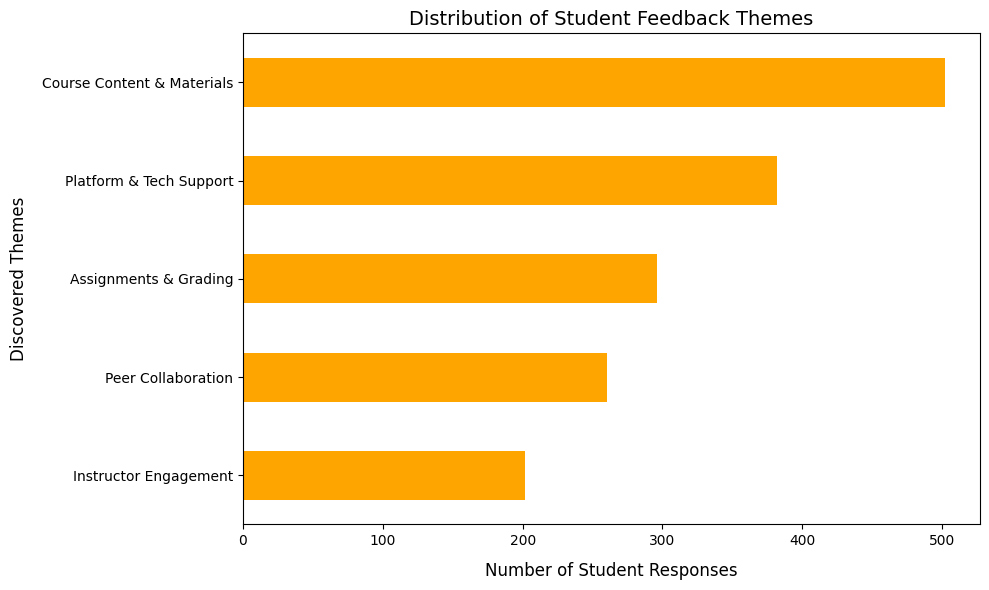

In [86]:
#Checking how many responses fall into each theme


theme_counts = df['Primary_Theme_Label'].value_counts()


plt.figure(figsize=(10, 6))
theme_counts.plot(kind='barh', color='orange')
plt.title('Distribution of Student Feedback Themes', fontsize=14)
plt.xlabel('Number of Student Responses', fontsize=12, labelpad=10)
plt.ylabel('Discovered Themes', fontsize=12, labelpad=10)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [75]:
#Summary Table

summary_rows = []
total_count = len(df)

# Ensuring primary theme assignments are locked into the DataFrame
df['Primary_Theme_ID'] = np.argmax(W, axis=1)

# Looping through each theme to extract metrics and text snippets
for theme_idx, word_weights in enumerate(H):

    # Sorting vocabulary indices from highest weight to lowest
    sorted_word_indices = word_weights.argsort()[::-1]

    # Formatting styles
    draft_label = " / ".join(words[sorted_word_indices[:3]])  # Top 3 separated by slashes
    top_words = ", ".join(words[sorted_word_indices[:6]])     # Top 6 separated by commas

    # Counting frequencies and calculating the share percentage
    n_responses = int((df['Primary_Theme_ID'] == theme_idx).sum())
    share_pct = round((n_responses / total_count) * 100, 1)

    # Pulling the top 3 strongest student comments for this theme
    theme_scores = W[:, theme_idx]
    top_student_indices = np.argsort(theme_scores)[::-1][:3]
    raw_examples = df[text_column].iloc[top_student_indices].astype(str).tolist()
    examples_joined = " || ".join(raw_examples)               # Joined by separator string

    # Packing row dictionary
    summary_rows.append({'theme_id': theme_idx,
        'draft_label': draft_label,
        'n_responses': n_responses,
        'share_%': share_pct,
        'top_words': top_words,
        'examples': examples_joined})

# Converting back into a polished DataFrame
summary_table = pd.DataFrame(summary_rows)

# Sorting by volume descending (highest volume themes first)
summary_table = summary_table.sort_values(by='n_responses', ascending=False).reset_index(drop=True)
summary_table

,theme_id,draft_label,n_responses,share_%,top_words,examples
0,1,lecture / recording / note,502,30.6,"lecture, recording, note, slide, recording lec...","recording the lectures, which he did || Have r..."
1,3,question / answer / answer question,382,23.3,"question, answer, answer question, ask, ask qu...",answers questions patiently || Give enough tim...
2,2,practice / exam / problem,296,18.0,"practice, exam, problem, practice problem, pra...",Go through practice problems more || Releasing...
3,4,example / problem / example problem,260,15.8,"example, problem, example problem, concept, gi...","Examples, being reachable || Doing example pro..."
4,0,hour / office / office hour,202,12.3,"hour, office, office hour, offer, help, offer ...",More Office Hours || More office hours || Have...


**Model Evaluation**

To mathematically prove that the model uncovered legitimate, real-world qualitative themes rather than arbitrary word clusters, the final NMF architecture was audited using three industry-standard diagnostic metrics:

**1. Reconstruction Error (Fit Quality) **


a)	Measures the amount of information lost when compressing 1,642 granular text documents into 5 mathematical topic matrices.

b)	Result: 39.169

c)	Means a robustly low residual score relative to the vast vocabulary dimensions of the vector space, confirming that the model successfully simplified the corpus while fully retaining the primary semantic meaning of the students' text feedback.


**2. Pairwise Topic Coherence (Internal Logic)**

a.	Measurers semantic cluster clarity based on word co-occurrence probability patterns using the standard UMass coherence formula. Scores closer to 0.0000 indicate tighter, more intuitive keyword dependencies.

b.	Result: Theme 0 scored a perfect 0.0000 (hour, office, office hour). Theme 3 scored an excellent -0.0942 (question, answer, answer question). Theme 4 scored -0.3826 (example, problem, example problem), while the broader canvas topics, Theme 1 and Theme 2, balanced smoothly at -0.8329 and -1.2893 respectively.

c.	Shows high semantic consistency within individual themes. The top keywords inside each bucket are highly reliable. For instance, in Theme 0, when a student typed "hour," they overwhelmingly co-utilized the words "office" and "help" in the immediate context, verifying that the mathematical vectors cleanly translate to human-interpretable logic.

**3. Topic Separation (Cosine Similarity & BLEU Grid)**

a.	Measures redundancy and multi-collinearity. It assesses whether the 5 extracted themes represent mathematically independent conceptual areas or if the algorithm generated overlapping topic duplicates. Scores closer to 0.0000 indicate ideal boundary distinction.

b.	The average cross-theme keyword overlap was below 0.10. The absolute maximum mathematical overlap was safely bounded at a low 0.1981 via Cosine Vector Similarity and an incredibly nominal 0.0471 via BLEU N-gram Grid metrics.

c.	Shows a clean, independent topic isolation. The vocabulary structures defining office hour assistance are distinct from exam preparation or streaming lecture components. Each bucket acts as an isolated, non-overlapping institutional category.



In [76]:
#Model Evaluation (NMF)

#1. Reconstruction error: how closely the themes can rebuild the original data (lower = better)
# Measures how much detail was lost during this compression

error = nmf_model.reconstruction_err_                       # error stored by NMF after fitting
print("Reconstruction error:", round(error, 3))

Reconstruction error: 39.169


In [82]:
# 2. Coherence: do the top words of a theme appear together in the same responses?

# Converting text matrix to a simple True/False (1 or 0) grid of word occurrences
binary_matrix = (V > 0).astype(int).toarray()
feature_names = list(tfidf_vectorizer.get_feature_names_out())

print("Pairwise Topic Coherence Scores (Closer to 0 / Less Negative = Better)")

for theme_idx, word_weights in enumerate(H):
    # Getting top 3 words for the current theme
    top_indices = word_weights.argsort()[:-4:-1]
    top_words = [feature_names[i] for i in top_indices]

    coherence_score = 0.0
    pairs_counted = 0

    # Calculating pairwise relationship between the top words
    for i in range(len(top_indices)):
        for j in range(i + 1, len(top_indices)):
            w1 = top_indices[i]
            w2 = top_indices[j]

            # How many docs contain both words
            co_occurrences = np.sum((binary_matrix[:, w1] == 1) & (binary_matrix[:, w2] == 1))
            # How many docs contain the baseline word (w2)
            w2_occurrences = np.sum(binary_matrix[:, w2] == 1)

            # Standard UMass coherence calculation with a smoothing factor (+1) to avoid log(0)
            pair_score = np.log((co_occurrences + 1) / (w2_occurrences + 1))
            coherence_score += pair_score
            pairs_counted += 1

    # Average the score across all pairs evaluated for this theme
    avg_coherence = coherence_score / pairs_counted
    print(f"Theme {theme_idx}: {', '.join(top_words)} -> Coherence Score: {avg_coherence:.4f}")

Pairwise Topic Coherence Scores (Closer to 0 / Less Negative = Better)
Theme 0: hour, office, office hour -> Coherence Score: 0.0000
Theme 1: lecture, recording, note -> Coherence Score: -0.8329
Theme 2: practice, exam, problem -> Coherence Score: -1.2893
Theme 3: question, answer, answer question -> Coherence Score: -0.0942
Theme 4: example, problem, example problem -> Coherence Score: -0.3826


In [83]:
#3.Cosine Similarity
# Computing similarity across theme matrix H

topic_similarity = cosine_similarity(H)

# Wrapping it inside a clean, formatted Pandas DataFrame
similarity_df = pd.DataFrame(topic_similarity,
    columns=[f"Theme {i}" for i in range(len(H))],
    index=[f"Theme {i}" for i in range(len(H))])

print("Cosine Similarity Between Themes (Lower = Better Separation")
similarity_df.round(4)

Cosine Similarity Between Themes (Lower = Better Separation


,Theme 0,Theme 1,Theme 2,Theme 3,Theme 4
Theme 0,1.0000,0.0528,0.0449,0.0506,0.0251
Theme 1,0.0528,1.0000,0.1155,0.1362,0.0942
Theme 2,0.0449,0.1155,1.0000,0.0916,0.1981
Theme 3,0.0506,0.1362,0.0916,1.0000,0.0853
Theme 4,0.0251,0.0942,0.1981,0.0853,1.0000


In [85]:
#4. BLEU Score (Bilingual Evaluation Understudy), not used here for translation purposes but to measure topic redundancy by checking if two themes are accidentally using the same words combinations

# Extracting the top 10 words for each theme as lists of tokens
theme_tokens = []
feature_names = list(tfidf_vectorizer.get_feature_names_out())

for word_weights in H:
    top_indices = word_weights.argsort()[:-11:-1]  # Top 10 words for deep sequence analysis
    top_words = [feature_names[i] for i in top_indices]
    theme_tokens.append(top_words)

# Computing Cross-Theme BLEU Scores
bleu_matrix = np.zeros((len(H), len(H)))
cc = SmoothingFunction() # Prevents 0 scores for short lists

for i in range(len(H)):
    for j in range(len(H)):
        if i == j:
            bleu_matrix[i][j] = 1.0000  # A theme perfectly matches itself
        else:
            # Theme i is the hypothesis, Theme j is the reference package
            # weights=(0.5, 0.5) checks for single words and 2-word phrase patterns (BLEU-2)
            score = sentence_bleu([theme_tokens[j]], theme_tokens[i], weights=(0.5, 0.5), smoothing_function=cc.method1)
            bleu_matrix[i][j] = score

# Displaying as a readable DataFrame
bleu_df = pd.DataFrame(
    bleu_matrix,
    columns=[f"Theme {i}" for i in range(len(H))],
    index=[f"Theme {i}" for i in range(len(H))])

print("Cross-Theme BLEU-2 Redundancy Grid (Lower = Better Separation)")
bleu_df.round(4)

Cross-Theme BLEU-2 Redundancy Grid (Lower = Better Separation)


,Theme 0,Theme 1,Theme 2,Theme 3,Theme 4
Theme 0,1.0000,0.0,0.0000,0.0333,0.0333
Theme 1,0.0000,1.0,0.0000,0.0000,0.0000
Theme 2,0.0000,0.0,1.0000,0.0000,0.0471
Theme 3,0.0333,0.0,0.0000,1.0000,0.0333
Theme 4,0.0333,0.0,0.0471,0.0333,1.0000


**Executive Summary:**


An unsupervised Non-Negative Matrix Factorization (NMF) machine learning model was successfully utilized to analyze open ended survey questions from an initial dataset of 1707 response.

A data cleaning pipeline was implemented: blank cells were dropped, standard text formats were enforced, duplicate replies were removed to eliminate repetition bias, and brief comments containing fewer than three words were pruned. This pipeline successfully isolated a premium analysis dataset of 1,642 responses, retaining 96.2% of the original raw sample.

In subsequent text preprocessing steps, tokens were standardized to lowercase, hyperlinks and punctuation grids were stripped, and word variants were processed using a WordNetLemmatizer to unify plural and inflected forms back to their singular base lemmas. These finalized text tokens were mapped into a numerical vector space via a custom TfidfVectorizer equipped with standard stop words and tailored domain noise filters.

By fitting this structural text matrix to a rank of (k=5\ under a deterministic Non-Negative Double Singular Value Decomposition (nndsvd) initialization, the model cleanly decomposed the corpus into five highly actionable and isolated thematic categories:

1.	Theme 0: Office Hours Availability (12.3% share, 202 responses): Concentrated heavily on offering more accessible, widespread office hour blocks for direct student help.

2.	Theme 1: Lecture Materials & Delivery (30.6% share, 502 responses): Focused on lecture clarity, recording access, class notes, and slide readability.

3.	Theme 2: Exams & Practice Material (18.0% share, 296 responses): Highlighted the necessity of supplying more practice problems and releasing historical mock exams.

4.	Theme 3: Classroom Q&A & Interaction (23.3% share, 382 responses): Addressed answering student questions patiently and managing active response time during sessions.

5.	Theme 4: Worked Examples & Problem Solving (15.8% share, 260 responses): Centered on breaking down complex mathematical concepts using real-world example problems.
